In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp




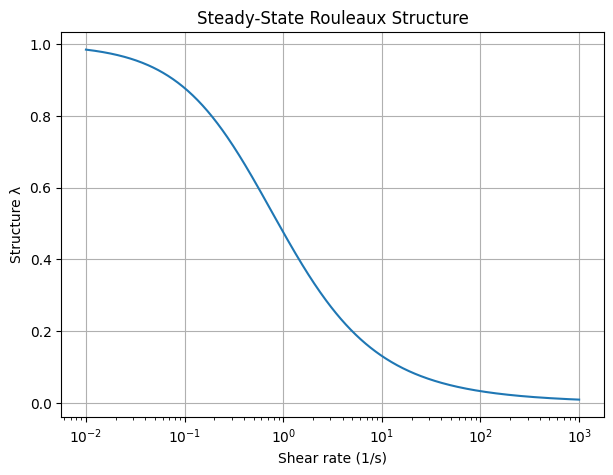

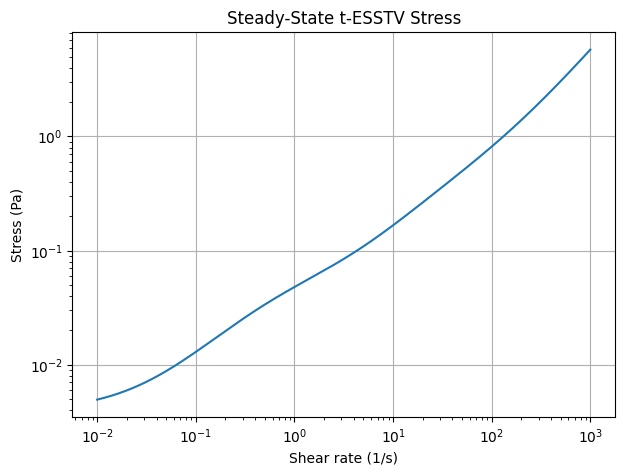

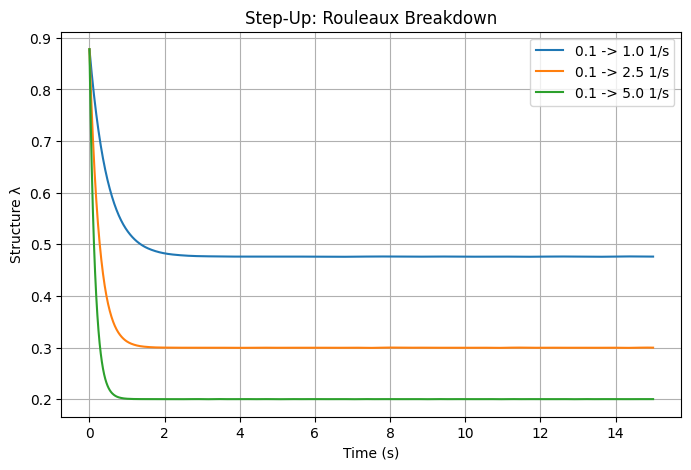

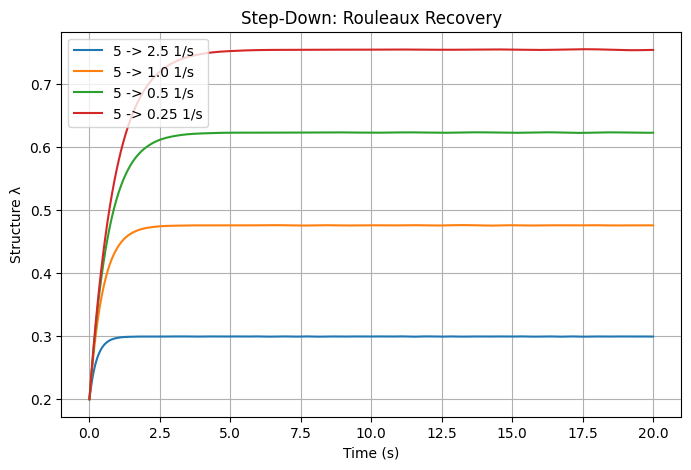

Shear rate | lambda | stress
----------------------------
      0.10 |  0.878 |  0.01295 Pa
      0.25 |  0.755 |  0.02262 Pa
      0.50 |  0.623 |  0.03364 Pa
      1.00 |  0.476 |  0.04795 Pa
      2.50 |  0.300 |  0.07486 Pa
      5.00 |  0.200 |  0.10880 Pa
     10.00 |  0.131 |  0.16659 Pa
    100.00 |  0.033 |  0.81459 Pa


In [2]:
# ============================================================
# 1. Parameters from the paper
#    Armstrong et al. (2022), Donor 5
# ============================================================

# ----- Plasma + individual RBC contribution -----

mu_zero = 0.0138
# Zero-shear viscosity, Pa.s
# Very low shear rate -> viscosity is close to this value

mu_inf = 0.0054
# Infinite-shear viscosity, Pa.s
# Very high shear rate -> viscosity approaches this value

tau_cross = 0.029
# Controls how quickly viscosity changes with shear rate


# ----- Rouleaux structure contribution -----

tau_break = 1.582
# Controls shear-induced rouleaux breakdown

tau_build = 0.192
# Controls shear-related rouleaux aggregation / buildup

mu_rouleaux = 0.099
# Extra viscosity caused by rouleaux structure, Pa.s

yield_stress = 0.0039
# Yield-stress contribution from rouleaux, Pa

tau_structure = 1.4582
# Controls how fast the structure variable lambda changes with time


# ----- Fixed parameters used for human blood -----

d = 0.5
# Aggregation exponent

m = 1.5
# Rouleaux viscosity exponent


# ============================================================
# 2. Plasma / RBC viscosity
# ============================================================

def plasma_viscosity(shear_rate):
    """
    Calculate the viscosity contribution from plasma
    and individual red blood cells.

    Input:
        shear_rate : shear rate, 1/s

    Output:
        viscosity : Pa.s
    """

    shear_rate = np.asarray(shear_rate)

    viscosity = (
        mu_inf
        + (mu_zero - mu_inf)
        / (1 + tau_cross * np.abs(shear_rate))
    )

    return viscosity


# ============================================================
# 3. Steady-state rouleaux structure
# ============================================================

def steady_structure(shear_rate):
    """
    Calculate steady-state rouleaux structure lambda.

    lambda = 1:
        strong rouleaux structure

    lambda = 0:
        rouleaux are mostly broken down

    Higher shear rate generally gives lower lambda.
    """

    shear_rate = np.asarray(shear_rate)

    build_term = np.abs(tau_build * shear_rate) ** d + 1

    break_term = tau_break * np.abs(shear_rate)

    lam = build_term / (break_term + build_term)

    return lam


# ============================================================
# 4. Steady-state total stress
# ============================================================

def steady_stress(shear_rate):
    """
    Calculate steady-state total stress.

    Total stress =
        plasma/RBC stress
        + rouleaux viscous stress
        + rouleaux yield stress
    """

    shear_rate = np.asarray(shear_rate)

    lam = steady_structure(shear_rate)

    # Stress from plasma + individual RBCs
    plasma_stress = plasma_viscosity(shear_rate) * shear_rate

    # Extra viscous stress caused by rouleaux
    rouleaux_viscous_stress = (
        mu_rouleaux
        * lam ** m
        * shear_rate
    )

    # Yield-stress contribution caused by rouleaux
    rouleaux_yield_stress = (
        yield_stress
        * lam
        * np.sign(shear_rate)
    )

    total_stress = (
        plasma_stress
        + rouleaux_viscous_stress
        + rouleaux_yield_stress
    )

    return total_stress


# ============================================================
# 5. Structure evolution equation
# ============================================================

def structure_change(t, y, shear_rate):
    """
    Calculate d(lambda)/dt.

    This tells us whether rouleaux are:
        building up   -> d(lambda)/dt > 0
        breaking down -> d(lambda)/dt < 0

    Simplification used here:
        plastic shear rate ≈ applied shear rate

    The full t-ESSTV model separates elastic
    and plastic deformation.
    """

    lam = y[0]

    # How strongly the existing rouleaux are being broken down
    breakdown = (
        lam
        * tau_break
        * abs(shear_rate)
    )

    # How strongly new rouleaux can build up
    buildup = (
        (1 - lam)
        * (
            abs(tau_build * shear_rate) ** d
            + 1
        )
    )

    dlam_dt = (
        buildup - breakdown
    ) / tau_structure

    return [dlam_dt]


# ============================================================
# 6. Simulate a step change in shear rate
# ============================================================

def simulate_shear_step(
    initial_shear,
    final_shear,
    duration=20,
    number_of_points=1000
):
    """
    Simulate what happens to lambda after shear rate changes.

    Example:
        initial_shear = 5
        final_shear   = 0.25

    This represents a step-down:
        5 -> 0.25 1/s
    """

    # Before the step change, assume blood has reached
    # steady state at the initial shear rate
    initial_lambda = float(
        steady_structure(initial_shear)
    )

    time_points = np.linspace(
        0,
        duration,
        number_of_points
    )

    result = solve_ivp(
        fun=lambda t, y:
            structure_change(
                t,
                y,
                final_shear
            ),

        t_span=(0, duration),

        y0=[initial_lambda],

        t_eval=time_points
    )

    time = result.t
    lam = result.y[0]

    # Lambda should physically stay between 0 and 1
    lam = np.clip(lam, 0, 1)

    return time, lam


# ============================================================
# 7. Plot steady-state lambda
# ============================================================

shear_rates = np.logspace(
    -2,
    3,
    500
)

lambda_values = steady_structure(
    shear_rates
)

plt.figure(figsize=(7, 5))

plt.semilogx(
    shear_rates,
    lambda_values
)

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Structure λ")

plt.title(
    "Steady-State Rouleaux Structure"
)

plt.grid(True)

plt.show()


# ============================================================
# 8. Plot steady-state stress
# ============================================================

stress_values = steady_stress(
    shear_rates
)

plt.figure(figsize=(7, 5))

plt.loglog(
    shear_rates,
    stress_values
)

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "Steady-State t-ESSTV Stress"
)

plt.grid(True)

plt.show()


# ============================================================
# 9. Step-up experiment
#
#    Low shear -> high shear
#    Expect:
#        more rouleaux breakdown
#        lambda decreases
# ============================================================

step_up_shear_rates = [
    1.0,
    2.5,
    5.0
]

plt.figure(figsize=(8, 5))

for final_shear in step_up_shear_rates:

    time, lam = simulate_shear_step(
        initial_shear=0.1,
        final_shear=final_shear,
        duration=15
    )

    plt.plot(
        time,
        lam,
        label=f"0.1 -> {final_shear} 1/s"
    )

plt.xlabel("Time (s)")
plt.ylabel("Structure λ")

plt.title(
    "Step-Up: Rouleaux Breakdown"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 10. Step-down experiment
#
#     High shear -> low shear
#     Expect:
#         rouleaux rebuild
#         lambda increases
# ============================================================

step_down_shear_rates = [
    2.5,
    1.0,
    0.5,
    0.25
]

plt.figure(figsize=(8, 5))

for final_shear in step_down_shear_rates:

    time, lam = simulate_shear_step(
        initial_shear=5.0,
        final_shear=final_shear,
        duration=20
    )

    plt.plot(
        time,
        lam,
        label=f"5 -> {final_shear} 1/s"
    )

plt.xlabel("Time (s)")
plt.ylabel("Structure λ")

plt.title(
    "Step-Down: Rouleaux Recovery"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 11. Print some numerical values
# ============================================================

test_shear_rates = [
    0.1,
    0.25,
    0.5,
    1.0,
    2.5,
    5.0,
    10.0,
    100.0
]

print(
    "Shear rate | lambda | stress"
)

print(
    "----------------------------"
)

for shear_rate in test_shear_rates:

    lam = float(
        steady_structure(shear_rate)
    )

    stress = float(
        steady_stress(shear_rate)
    )

    print(
        f"{shear_rate:10.2f} | "
        f"{lam:6.3f} | "
        f"{stress:8.5f} Pa"
    )

### non-tensorial transient t-ESSTV solver

In [3]:
# ============================================================
# 1. Donor 5 parameters from the paper
# ============================================================

# ----- Plasma + individual RBC parameters -----

mu_zero = 0.0138
# Low-shear viscosity, Pa.s

mu_inf = 0.0054
# High-shear viscosity, Pa.s

tau_cross = 0.029
# Controls the shear-thinning transition

G_cell = 0.5138
# Elastic modulus of plasma + individual RBCs, Pa


# ----- Rouleaux parameters -----

tau_break = 1.582
# Controls rouleaux breakdown

tau_build = 0.192
# Controls rouleaux aggregation / rebuilding

mu_rouleaux = 0.099
# Viscous contribution from rouleaux, Pa.s

yield_stress = 0.0039
# Rouleaux yield-stress parameter, Pa

G_rouleaux = 0.2646
# Elastic modulus of rouleaux, Pa

tau_structure = 1.4582
# Time scale for rouleaux structure evolution, s


# ----- Fixed parameters for human blood -----

gamma0_rouleaux = 1.0
# Maximum elastic strain coefficient

d = 0.5
# Aggregation exponent

m = 1.5
# Structure-viscosity exponent

In [4]:
# ============================================================
# 2. Steady-state helper functions
# ============================================================

def cross_viscosity(shear_rate):
    """
    Plasma + individual RBC viscosity
    as a function of applied shear rate.
    """

    return (
        mu_inf
        + (mu_zero - mu_inf)
        / (1 + tau_cross * abs(shear_rate))
    )


def steady_structure(shear_rate):
    """
    Steady-state rouleaux structure lambda.

    lambda close to 1:
        strong rouleaux structure

    lambda close to 0:
        rouleaux mostly broken down
    """

    build = (
        abs(tau_build * shear_rate) ** d
        + 1
    )

    breakdown = (
        tau_break
        * abs(shear_rate)
    )

    lam = build / (breakdown + build)

    return lam

In [5]:
# ============================================================
# 3. Transient viscosity from normal stress
# ============================================================

def transient_viscosity(normal_stress):
    """
    Calculate the transient plasma/RBC viscosity
    from the current normal stress.

    This comes from the auxiliary equations
    in the non-tensorial t-ESSTV model.
    """

    # Prevent numerical problems if the solver
    # produces a tiny negative value
    normal_stress = max(normal_stress, 0.0)

    root_term = np.sqrt(
        G_cell * normal_stress / 2
    )

    b = (
        tau_cross * root_term
        - mu_zero
    )

    c = (
        -mu_inf
        * tau_cross
        * root_term
    )

    discriminant = (
        b ** 2
        - 4 * c
    )

    # Numerical protection
    discriminant = max(
        discriminant,
        1e-18
    )

    viscosity = (
        -b
        + np.sqrt(discriminant)
    ) / 2

    return max(
        viscosity,
        1e-8
    )

In [6]:
# ============================================================
# 4. Initial state before a shear-rate step
# ============================================================

def initial_state(initial_shear):
    """
    Create the initial state before the shear-rate step.

    We assume the blood has already reached steady state
    at the initial shear rate.
    """

    # Initial rouleaux structure
    lam = steady_structure(
        initial_shear
    )

    # Maximum elastic strain
    max_elastic_strain = (
        gamma0_rouleaux
        * lam
    )

    # At positive steady shear,
    # elastic strain approaches its maximum value
    elastic_strain = (
        max_elastic_strain
        * np.sign(initial_shear)
    )

    # Plasma/RBC steady viscosity
    viscosity = cross_viscosity(
        initial_shear
    )

    # Plasma/RBC shear stress
    cell_shear_stress = (
        viscosity
        * initial_shear
    )

    # Approximate steady normal stress
    cell_normal_stress = (
        2
        * viscosity ** 2
        * initial_shear ** 2
        / G_cell
    )

    # Rouleaux steady stress contribution
    rouleaux_stress = (
        mu_rouleaux
        * lam ** m
        * initial_shear

        + yield_stress
        * lam
        * np.sign(initial_shear)
    )

    return [
        lam,
        elastic_strain,
        cell_shear_stress,
        cell_normal_stress,
        rouleaux_stress
    ]

In [7]:
# ============================================================
# 5. Full non-tensorial transient equations
# ============================================================

def tesstv_equations(
    time,
    state,
    shear_rate
):

    """
    Non-tensorial transient t-ESSTV equations.

    State contains:

        lambda
        elastic strain
        plasma/RBC shear stress
        plasma/RBC normal stress
        rouleaux stress
    """

    (
        lam,
        elastic_strain,
        cell_shear_stress,
        cell_normal_stress,
        rouleaux_stress
    ) = state


    # --------------------------------------------------------
    # A. Keep lambda inside a physically meaningful range
    # --------------------------------------------------------

    lam_safe = np.clip(
        lam,
        1e-6,
        1.0
    )


    # --------------------------------------------------------
    # B. Maximum elastic strain of the rouleaux
    #
    # gamma_max = gamma0_R * lambda
    # --------------------------------------------------------

    max_elastic_strain = (
        gamma0_rouleaux
        * lam_safe
    )

    max_elastic_strain = max(
        max_elastic_strain,
        1e-6
    )


    # --------------------------------------------------------
    # C. Plastic shear rate
    #
    # This is NOT simply equal to applied shear rate.
    # It depends on the current elastic deformation.
    # --------------------------------------------------------

    denominator = (
        2
        - elastic_strain
        / max_elastic_strain
    )

    # Avoid division by zero
    if abs(denominator) < 1e-6:

        denominator = (
            1e-6
            if denominator >= 0
            else -1e-6
        )


    plastic_shear_rate = (
        shear_rate
        / denominator
    )


    # --------------------------------------------------------
    # D. Rouleaux structure evolution
    #
    # buildup - breakdown
    # --------------------------------------------------------

    breakdown = (
        tau_break
        * abs(plastic_shear_rate)
        * lam_safe
    )

    buildup = (
        (1 - lam_safe)
        * (
            abs(
                tau_build
                * plastic_shear_rate
            ) ** d
            + 1
        )
    )

    d_lambda = (
        buildup
        - breakdown
    ) / tau_structure


    # --------------------------------------------------------
    # E. Change in maximum elastic strain
    #
    # gamma_max = gamma0_R * lambda
    # --------------------------------------------------------

    d_max_elastic_strain = (
        gamma0_rouleaux
        * d_lambda
    )


    # --------------------------------------------------------
    # F. Elastic strain evolution
    # --------------------------------------------------------

    d_elastic_strain = (
        plastic_shear_rate

        - (
            elastic_strain
            / max_elastic_strain
        )
        * abs(plastic_shear_rate)
    )


    # When lambda is decreasing,
    # gamma_max is also shrinking.
    #
    # The paper adds this correction term.

    if d_max_elastic_strain < 0:

        d_elastic_strain += (
            elastic_strain
            / max_elastic_strain
        ) * d_max_elastic_strain


    # --------------------------------------------------------
    # G. Plasma + individual RBC transient viscosity
    # --------------------------------------------------------

    viscosity = transient_viscosity(
        cell_normal_stress
    )


    # --------------------------------------------------------
    # H. Plasma/RBC shear stress evolution
    #
    # White-Metzner viscoelastic contribution
    # --------------------------------------------------------

    d_cell_shear_stress = (
        G_cell
        * (
            shear_rate
            - cell_shear_stress
            / viscosity
        )
    )


    # --------------------------------------------------------
    # I. Plasma/RBC normal stress evolution
    # --------------------------------------------------------

    d_cell_normal_stress = (

        2
        * shear_rate
        * cell_shear_stress

        - G_cell
        * cell_normal_stress
        / viscosity
    )


    # --------------------------------------------------------
    # J. Rouleaux stress evolution
    #
    # Elasto-visco-plastic contribution
    # --------------------------------------------------------

    structure_viscosity = (
        lam_safe ** m
        * mu_rouleaux
    )

    structure_viscosity = max(
        structure_viscosity,
        1e-8
    )


    yield_part = (
        yield_stress
        / gamma0_rouleaux
        * elastic_strain
    )


    stress_difference = (
        rouleaux_stress
        - yield_part
    )


    # Direction of rouleaux stress
    if abs(rouleaux_stress) > 1e-10:

        stress_direction = np.sign(
            rouleaux_stress
        )

    else:

        stress_direction = np.sign(
            shear_rate
        )


    plastic_flow = (

        abs(stress_difference)
        / structure_viscosity

        * stress_direction
    )


    d_rouleaux_stress = (

        lam_safe
        * G_rouleaux

        * (
            shear_rate
            - plastic_flow
        )
    )


    return [

        d_lambda,

        d_elastic_strain,

        d_cell_shear_stress,

        d_cell_normal_stress,

        d_rouleaux_stress

    ]

In [8]:
# ============================================================
# 6. Simulate one shear-rate step
# ============================================================

def simulate_transient_step(
    initial_shear,
    final_shear,
    duration=10,
    number_of_points=1000
):

    """
    Simulate transient t-ESSTV response
    after an instantaneous shear-rate change.
    """

    start_state = initial_state(
        initial_shear
    )

    time_points = np.linspace(
        0,
        duration,
        number_of_points
    )

    result = solve_ivp(

        fun=lambda t, y:
            tesstv_equations(
                t,
                y,
                final_shear
            ),

        t_span=(
            0,
            duration
        ),

        y0=start_state,

        t_eval=time_points,

        # BDF is more stable for coupled rheology equations
        method="BDF",

        rtol=1e-7,
        atol=1e-9
    )


    if not result.success:

        print(
            "Solver failed:",
            result.message
        )


    time = result.t

    lam = result.y[0]

    elastic_strain = result.y[1]

    cell_stress = result.y[2]

    normal_stress = result.y[3]

    rouleaux_stress = result.y[4]


    # Total predicted transient stress
    total_stress = (
        cell_stress
        + rouleaux_stress
    )


    return {
        "time": time,
        "lambda": lam,
        "elastic_strain": elastic_strain,
        "cell_stress": cell_stress,
        "normal_stress": normal_stress,
        "rouleaux_stress": rouleaux_stress,
        "total_stress": total_stress
    }

In [9]:
# ============================================================
# 7. Example: step-up from 0.1 -> 5 1/s
# ============================================================

result = simulate_transient_step(
    initial_shear=0.1,
    final_shear=5.0,
    duration=10
)

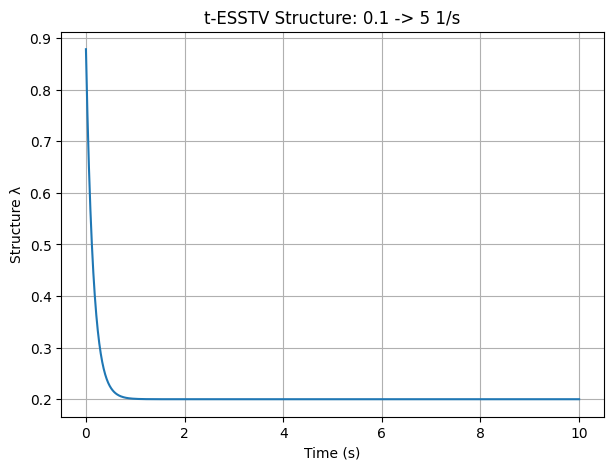

In [10]:
plt.figure(figsize=(7, 5))

plt.plot(
    result["time"],
    result["lambda"]
)

plt.xlabel("Time (s)")
plt.ylabel("Structure λ")

plt.title(
    "t-ESSTV Structure: 0.1 -> 5 1/s"
)

plt.grid(True)

plt.show()

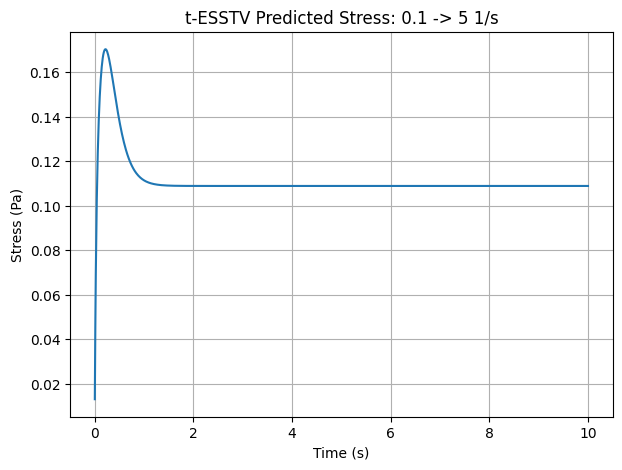

In [11]:
plt.figure(figsize=(7, 5))

plt.plot(
    result["time"],
    result["total_stress"]
)

plt.xlabel("Time (s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "t-ESSTV Predicted Stress: 0.1 -> 5 1/s"
)

plt.grid(True)

plt.show()

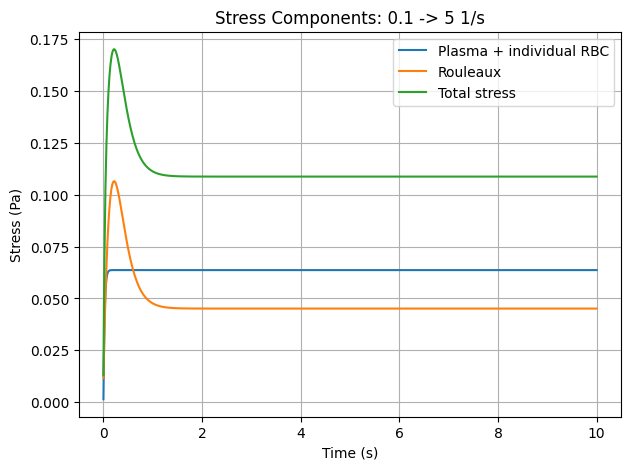

In [12]:
plt.figure(figsize=(7, 5))

plt.plot(
    result["time"],
    result["cell_stress"],
    label="Plasma + individual RBC"
)

plt.plot(
    result["time"],
    result["rouleaux_stress"],
    label="Rouleaux"
)

plt.plot(
    result["time"],
    result["total_stress"],
    label="Total stress"
)

plt.xlabel("Time (s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "Stress Components: 0.1 -> 5 1/s"
)

plt.legend()
plt.grid(True)

plt.show()

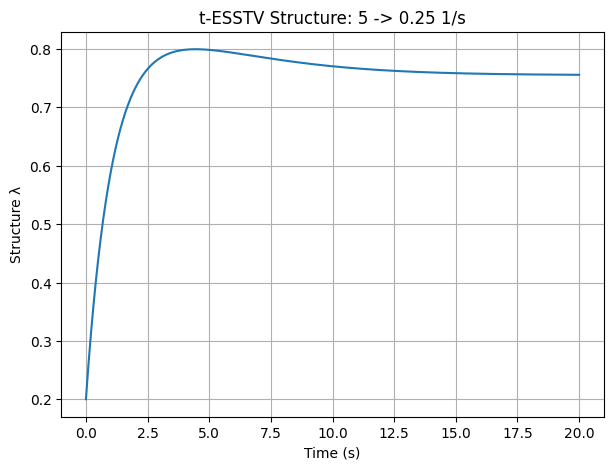

In [13]:
# ============================================================
# 8. Example: step-down from 5 -> 0.25 1/s
# ============================================================

result_down = simulate_transient_step(
    initial_shear=5.0,
    final_shear=0.25,
    duration=20
)


plt.figure(figsize=(7, 5))

plt.plot(
    result_down["time"],
    result_down["lambda"]
)

plt.xlabel("Time (s)")
plt.ylabel("Structure λ")

plt.title(
    "t-ESSTV Structure: 5 -> 0.25 1/s"
)

plt.grid(True)

plt.show()